# **Time Series and Forecasting - Final Project**
| Matheus Hirakawa Bissacot (up202106708) |
Bernardo Gil Alves Salgado (up202004493) |
Michal Dawid Kowalski (up202401554) |

## 1. Uploading Dataset

**Dataset:** 'Hourly Energy Consumption' link: https://www.kaggle.com/datasets/robikscube/hourly-energy-consumption/data

**Brief:** Over 10 years of hourly energy consumption data from PJM in Megawatts. 

**Characterisitcs:** PJM Hourly Energy Consumption Data.

PJM Interconnection LLC (PJM) is a regional transmission organization (RTO) in the United States. It is part of the Eastern Interconnection grid operating an electric transmission system serving all or parts of Delaware, Illinois, Indiana, Kentucky, Maryland, Michigan, New Jersey, North Carolina, Ohio, Pennsylvania, Tennessee, Virginia, West Virginia, and the District of Columbia.

The hourly power consumption data comes from PJM's website and are in megawatts (MW).

The regions have changed over the years so data may only appear for certain dates per region.

In [1]:
# Importing libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from scipy.fft import fft, fftfreq
from scipy.signal import periodogram
from statsmodels.tsa.stattools import acf
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.graphics.tsaplots import plot_pacf
from statsmodels.tsa.arima.model import ARIMA

- Electricity usage for the **American Electric Power**

In [2]:
# Upload dataset AEP_hourly.csv
df_aep = pd.read_csv('archive/AEP_hourly.csv')

df_aep.set_index('Datetime', inplace =True) # Set datatime as the Dataframe index
df_aep.index = pd.to_datetime(df_aep.index) # Datatime format
df_aep = df_aep.sort_index() # Sort indexes

In [3]:
df_aep.head(5) # Display first 5 rows

,AEP_MW
Datetime,
2004-10-01 01:00:00,12379.0
2004-10-01 02:00:00,11935.0
2004-10-01 03:00:00,11692.0
2004-10-01 04:00:00,11597.0
2004-10-01 05:00:00,11681.0


In [4]:
df_aep.info() # Basic Dataset info

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 121273 entries, 2004-10-01 01:00:00 to 2018-08-03 00:00:00
Data columns (total 1 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   AEP_MW  121273 non-null  float64
dtypes: float64(1)
memory usage: 1.9 MB


In [5]:
# Check the time range
min_time = df_aep.index.min()
max_time = df_aep.index.max()
print ('Time range:\n')
print(f" Start Time: {min_time}")
print(f" End Time: {max_time}")
print(f" Time Range: {max_time - min_time}")

Time range:

 Start Time: 2004-10-01 01:00:00
 End Time: 2018-08-03 00:00:00
 Time Range: 5053 days 23:00:00


In [6]:
# Missing values checker
df_aep.isna().sum()

AEP_MW    0
dtype: int64

- No missing values in the dataset.

In [7]:
df_aep.describe() # Statistical Characteristics

,AEP_MW
count,121273.000000
mean,15499.513717
std,2591.399065
min,9581.000000
25%,13630.000000
50%,15310.000000
75%,17200.000000
max,25695.000000


## 2. Data Visualisation & Features Extraction

In this section, we carry out the dataset visualization which is a critical step in time series analysis. It helps us understand the nature of the data and identify key patterns or characteristics.

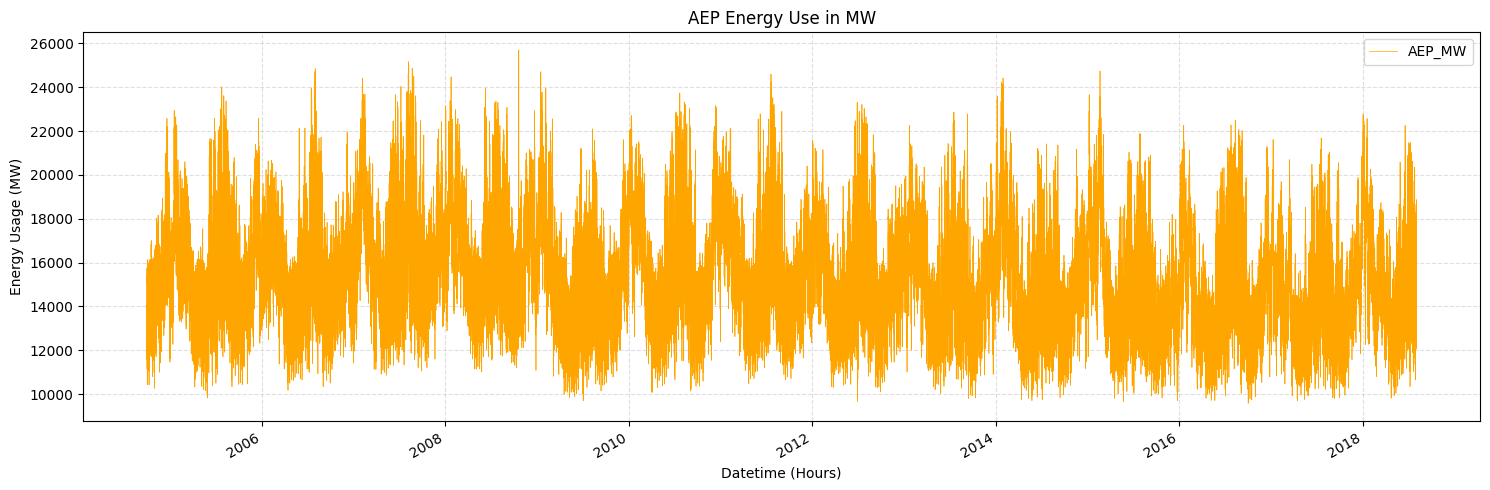

In [8]:
# Timeserie diagram
df_aep.plot(
    figsize=(15, 5),
    color='orange',
    linewidth=0.5,
    title='AEP Energy Use in MW',
    xlabel='Datetime (Hours)',
    ylabel='Energy Usage (MW)'
)
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

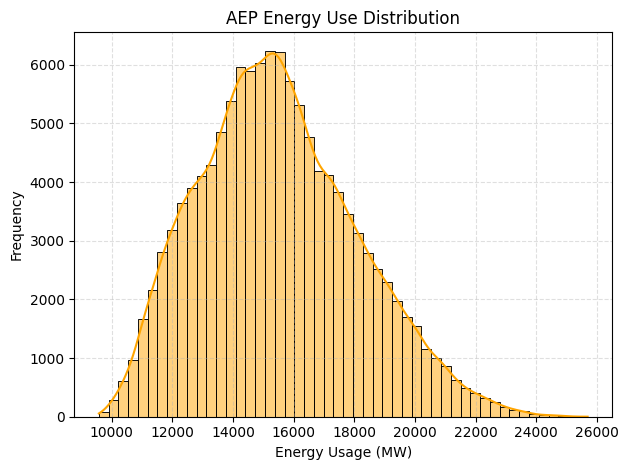

In [9]:
# Energy Usage Distribution
sns.histplot(
    data=df_aep, 
    x='AEP_MW', 
    kde=True, 
    bins=50, 
    color='orange', 
)

plt.title('AEP Energy Use Distribution')
plt.xlabel('Energy Usage (MW)')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

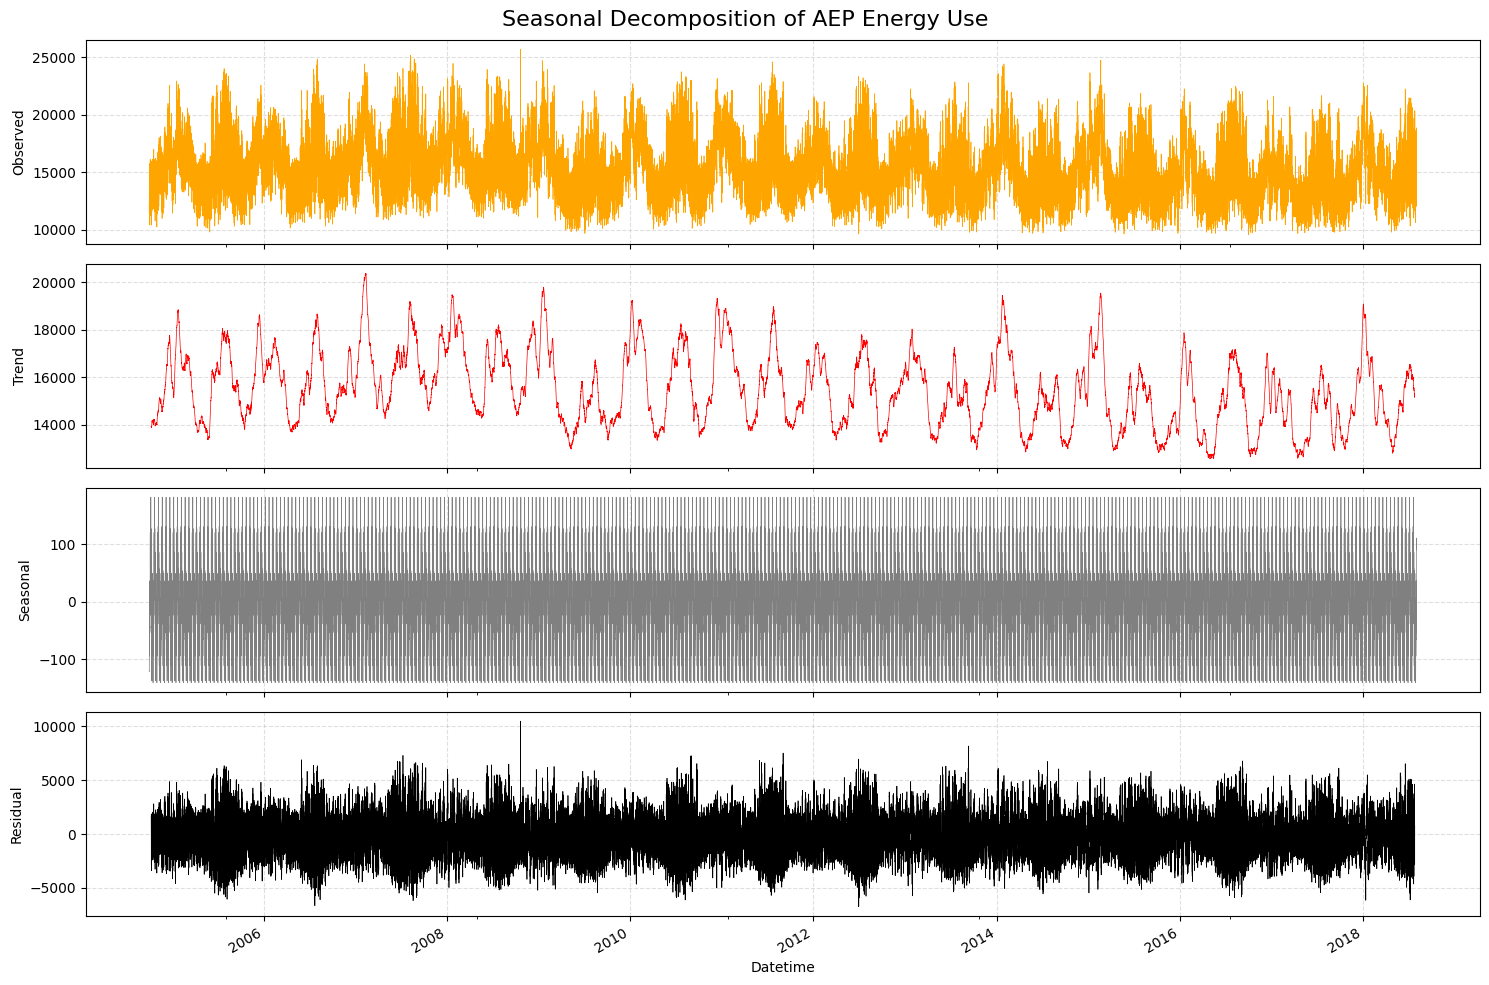

In [10]:
# Datatime Decomposition
result = seasonal_decompose(df_aep['AEP_MW'], period=365)

# Remove the seasonal component from the series
df_aep['AEP_MW_detrended'] = df_aep['AEP_MW'] - result.seasonal

fig, axes = plt.subplots(4, 1, figsize=(15, 10), sharex=True)

# Observed part
result.observed.plot(ax=axes[0], color='orange', linewidth=0.5)
axes[0].set_ylabel('Observed')
axes[0].grid(True, linestyle='--', alpha=0.4)

# Trend part
result.trend.plot(ax=axes[1], color='red', linewidth=0.5)
axes[1].set_ylabel('Trend')
axes[1].grid(True, linestyle='--', alpha=0.4)

# Seasonal part
result.seasonal.plot(ax=axes[2], color='grey', linewidth=0.5)
axes[2].set_ylabel('Seasonal')
axes[2].grid(True, linestyle='--', alpha=0.4)

# Residual part
result.resid.plot(ax=axes[3], color='black', linewidth=0.5)
axes[3].set_ylabel('Residual')
axes[3].grid(True, linestyle='--', alpha=0.4)

plt.suptitle('Seasonal Decomposition of AEP Energy Use', fontsize=16)
plt.xlabel('Datetime')
plt.tight_layout()
plt.show()

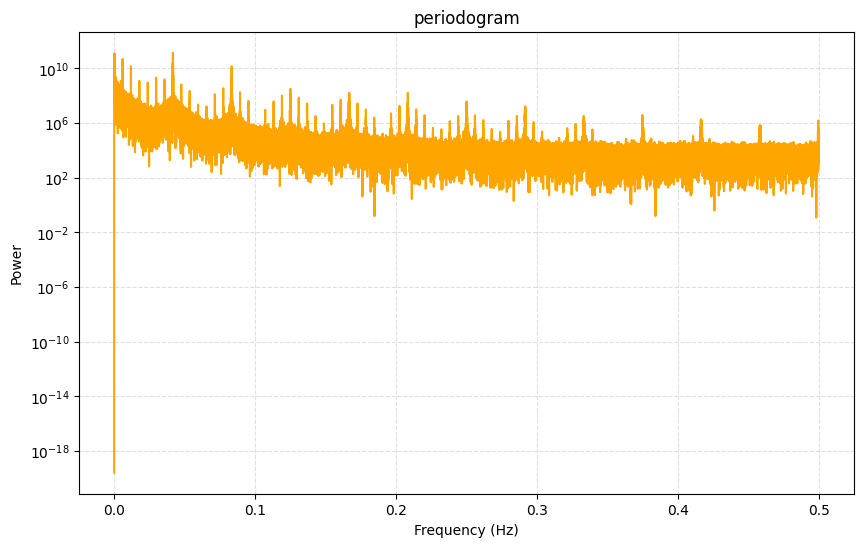

In [11]:
# Compute the periodogram
frequencies, power = periodogram(df_aep['AEP_MW_detrended'].dropna(), fs=1)

# Plot the periodogram
plt.figure(figsize=(10, 6))
plt.semilogy(frequencies, power, color='orange')
plt.title('periodogram')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Power')
plt.grid(True, linestyle='--', alpha=0.4)
plt.show()

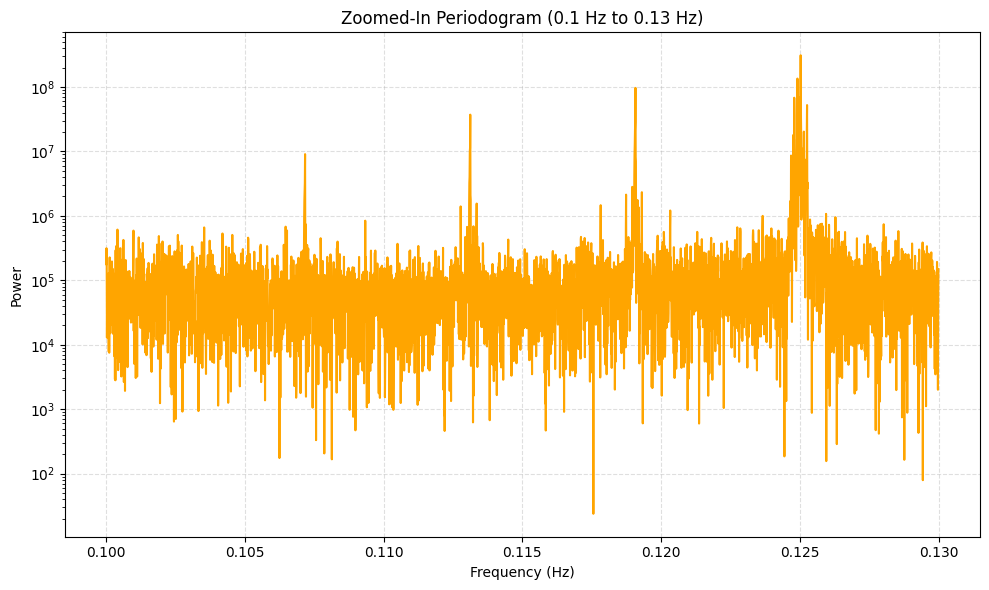

In [12]:
# Compute the periodogram again to show the zoomed in version
frequencies, power = periodogram(df_aep['AEP_MW_detrended'].dropna(), fs=1)

# Define the frequency range to zoom in (0.1 to 0.13 Hz)
freq_range = (frequencies >= 0.1) & (frequencies <= 0.13)

# Filter the frequencies and power values within the specified range
filtered_frequencies = frequencies[freq_range]
filtered_power = power[freq_range]

# Plot the zoomed-in periodogram
plt.figure(figsize=(10, 6))
plt.semilogy(filtered_frequencies, filtered_power, color='orange')
plt.title('Zoomed-In Periodogram (0.1 Hz to 0.13 Hz)')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Power')
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

In [13]:
# Features Creating (for deeper data explorting)

df_aep['hour']=df_aep.index.hour     # hours
df_aep['day']=df_aep.index.dayofweek # days, where: 0 - Monday, 1 - Tuesday, 2 - Wednesday, 3 - Thrusday, 4 - Friday, 5 - Saturday, 6 - Sunday
df_aep['month']=df_aep.index.month   # months
df_aep['year']=df_aep.index.year     # years

# Function to get seasons
def get_season(month):
    if month in [12, 1, 2]:
        return 3
    if month in [3, 4, 5]:
        return 0
    if month in [6, 7, 8]:
        return 1
    if month in [9, 10, 11]:
        return 2

df_aep['season'] = df_aep['month'].apply(get_season) # seasons, where: 0 - spring, 1 - summer, 2 - autumn, 3 - winter


In [14]:
df_aep.head(5) # Feautres Display

,AEP_MW,AEP_MW_detrended,hour,day,month,year,season
Datetime,,,,,,,
2004-10-01 01:00:00,12379.0,12500.218889,1,4,10,2004,2
2004-10-01 02:00:00,11935.0,12056.581832,2,4,10,2004,2
2004-10-01 03:00:00,11692.0,11802.788818,3,4,10,2004,2
2004-10-01 04:00:00,11597.0,11704.407326,4,4,10,2004,2
2004-10-01 05:00:00,11681.0,11771.633630,5,4,10,2004,2


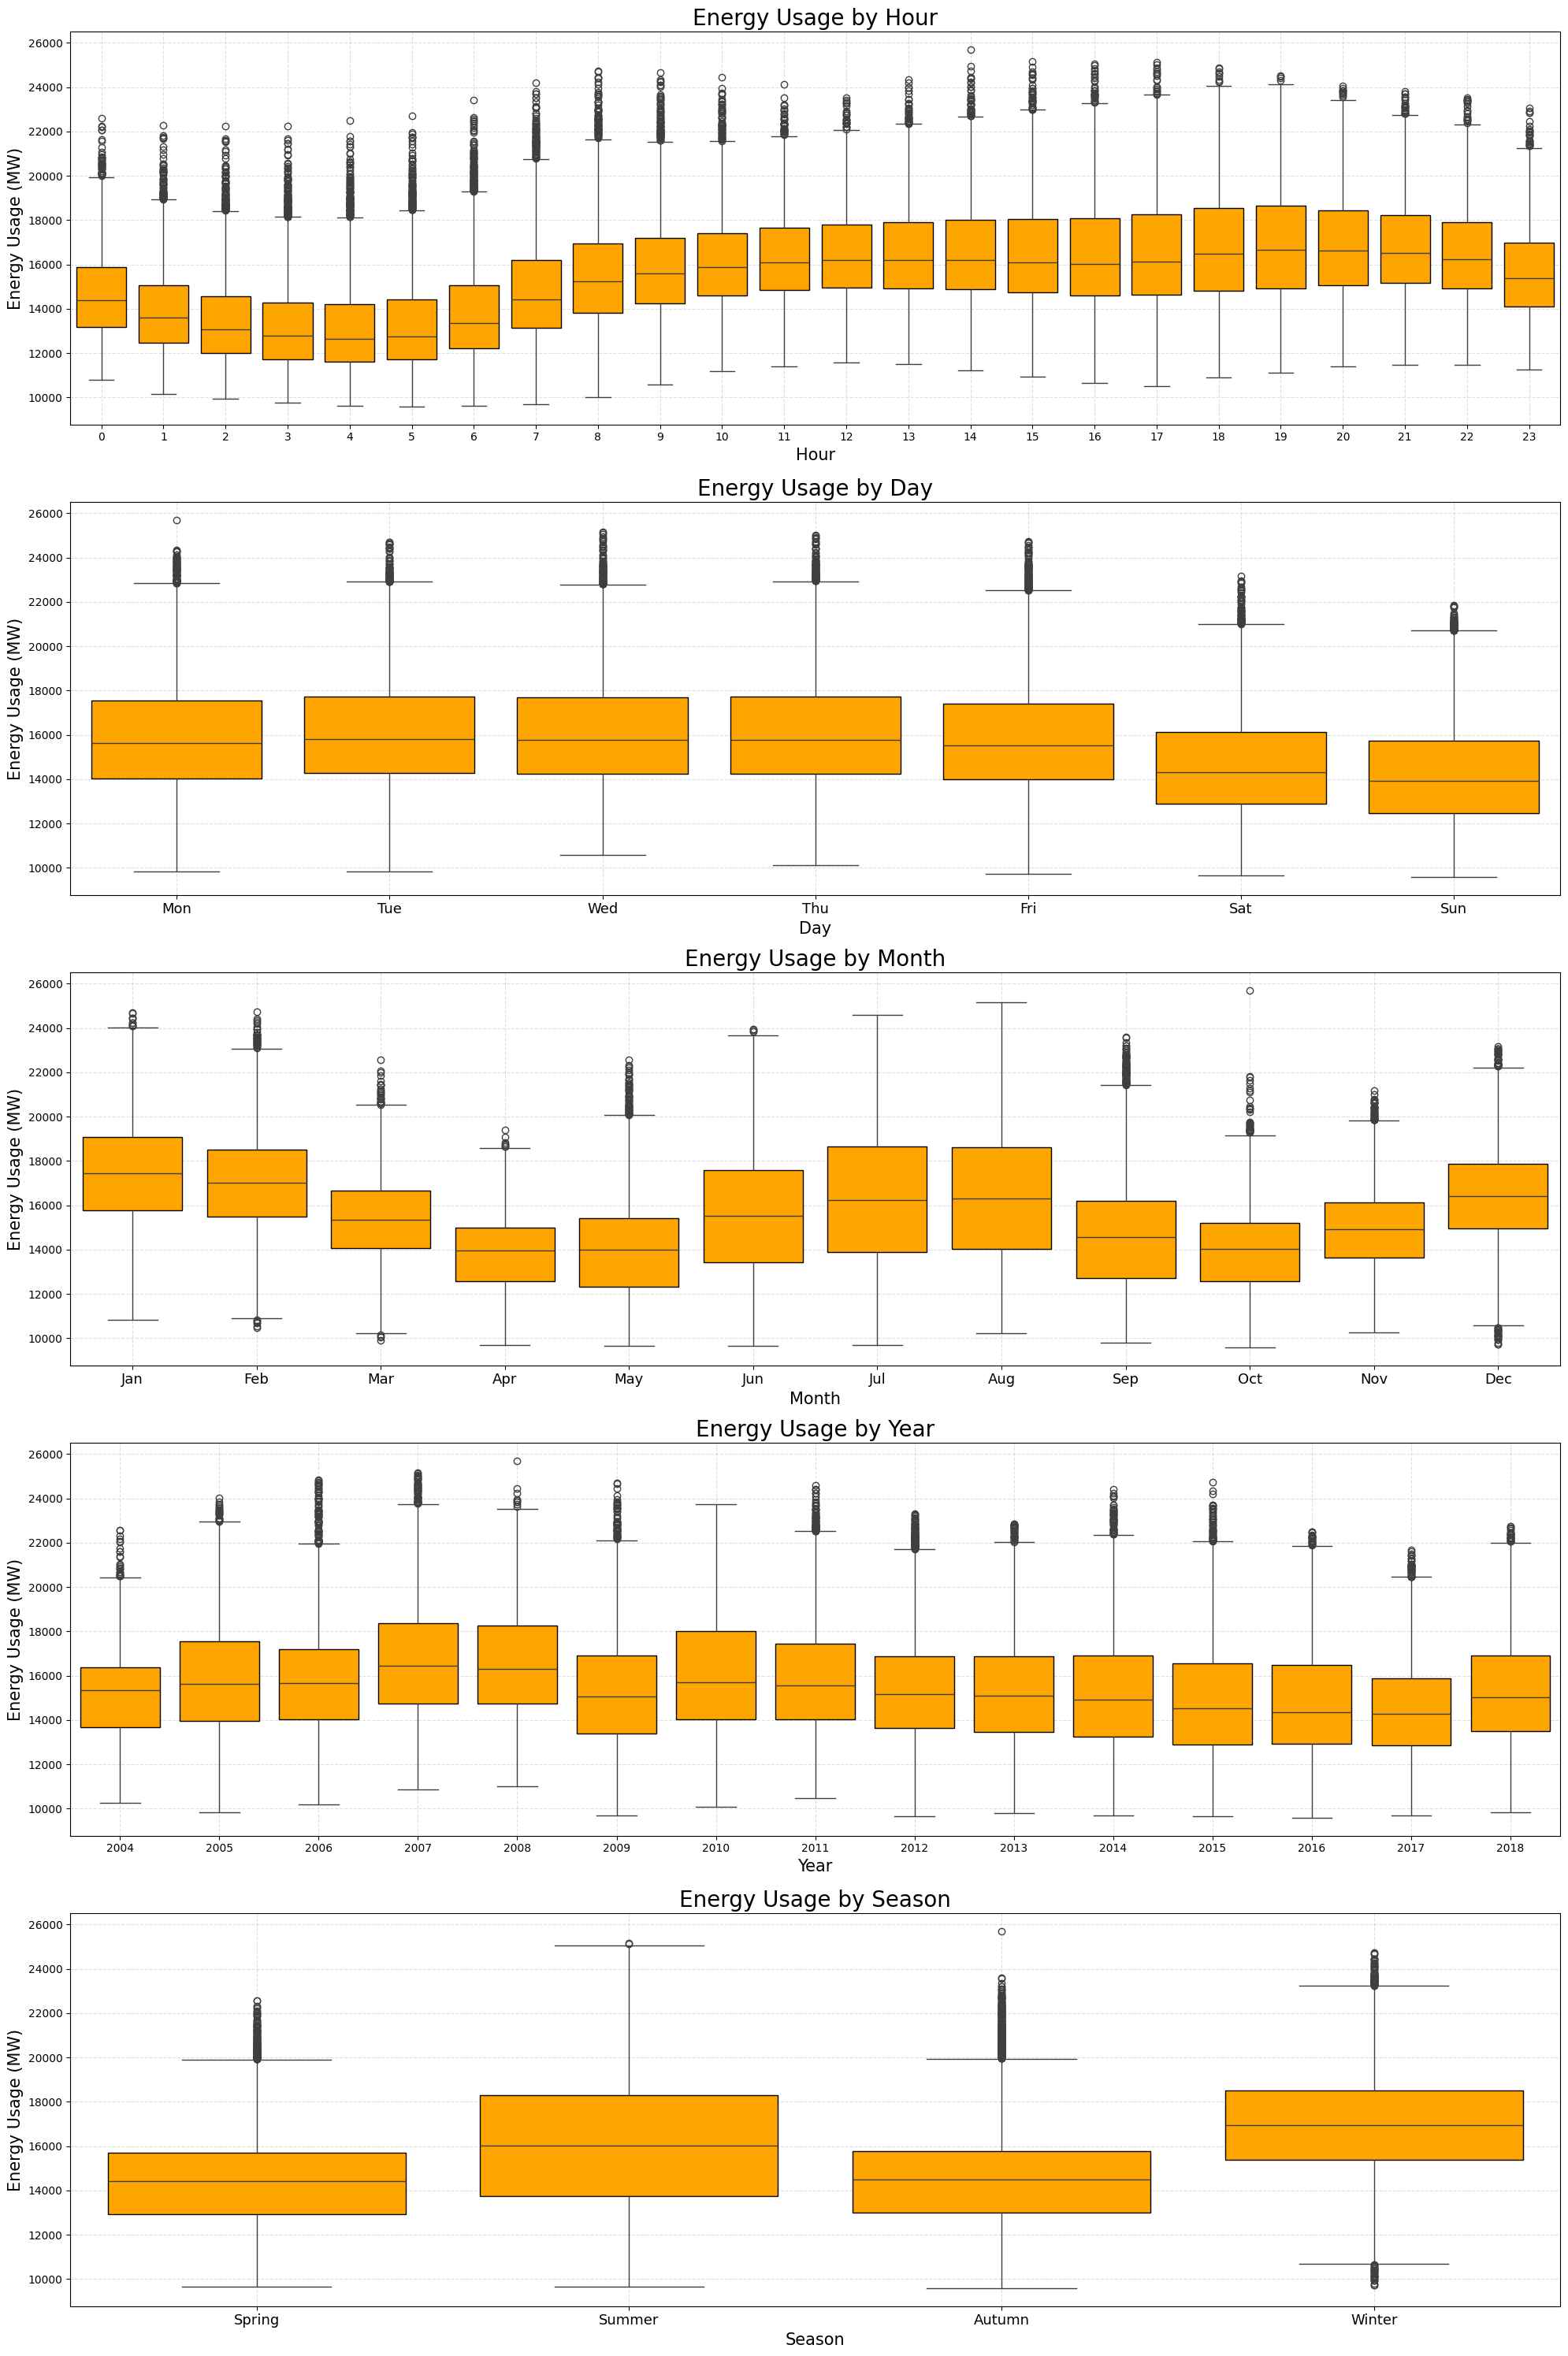

In [15]:
# Boxplots
fig, axes = plt.subplots(5, 1, figsize=(20, 30), sharex=False)

# Energy Usage by Hour
sns.boxplot(data=df_aep, x='hour', y='AEP_MW', ax=axes[0], boxprops=dict(facecolor='orange', edgecolor='black'))
axes[0].set_title('Energy Usage by Hour', fontsize=20)
axes[0].set_xlabel('Hour', fontsize = 15)
axes[0].set_ylabel('Energy Usage (MW)', fontsize = 15)
axes[0].grid(True, linestyle='--', alpha=0.4)

# Energy Usage by Day
sns.boxplot(data=df_aep, x='day', y='AEP_MW', ax=axes[1], boxprops=dict(facecolor='orange', edgecolor='black'))
axes[1].set_title('Energy Usage by Day', fontsize=20)
axes[1].set_xlabel('Day', fontsize = 15)
axes[1].set_ylabel('Energy Usage (MW)', fontsize = 15)
axes[1].set_xticks(range(0, 7))
axes[1].set_xticklabels(
    ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'], fontsize = 13)
axes[1].grid(True, linestyle='--', alpha=0.4)

# Energy Usage by Month
sns.boxplot(data=df_aep, x='month', y='AEP_MW', ax=axes[2], boxprops=dict(facecolor='orange', edgecolor='black'))
axes[2].set_title('Energy Usage by Month', fontsize=20)
axes[2].set_xlabel('Month', fontsize = 15)
axes[2].set_ylabel('Energy Usage (MW)', fontsize = 15)
axes[2].set_xticks(range(0, 12))
axes[2].set_xticklabels(
    ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 
    'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'], fontsize = 13)
axes[2].grid(True, linestyle='--', alpha=0.4)

# Energy Usage by Year
sns.boxplot(data=df_aep, x='year', y='AEP_MW', ax=axes[3], boxprops=dict(facecolor='orange', edgecolor='black'))
axes[3].set_title('Energy Usage by Year', fontsize=20)
axes[3].set_xlabel('Year', fontsize = 15)
axes[3].set_ylabel('Energy Usage (MW)', fontsize = 15)
axes[3].grid(True, linestyle='--', alpha=0.4)

# Energy Usage by Season
sns.boxplot(data=df_aep, x='season', y='AEP_MW', ax=axes[4], boxprops=dict(facecolor='orange', edgecolor='black'))
axes[4].set_title('Energy Usage by Season', fontsize=20)
axes[4].set_xlabel('Season', fontsize = 15)
axes[4].set_ylabel('Energy Usage (MW)', fontsize = 15)
axes[4].set_xticks(range(0, 4))
axes[4].set_xticklabels(
    ['Spring', 'Summer', 'Autumn', 'Winter'], fontsize = 13)
axes[4].grid(True, linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()

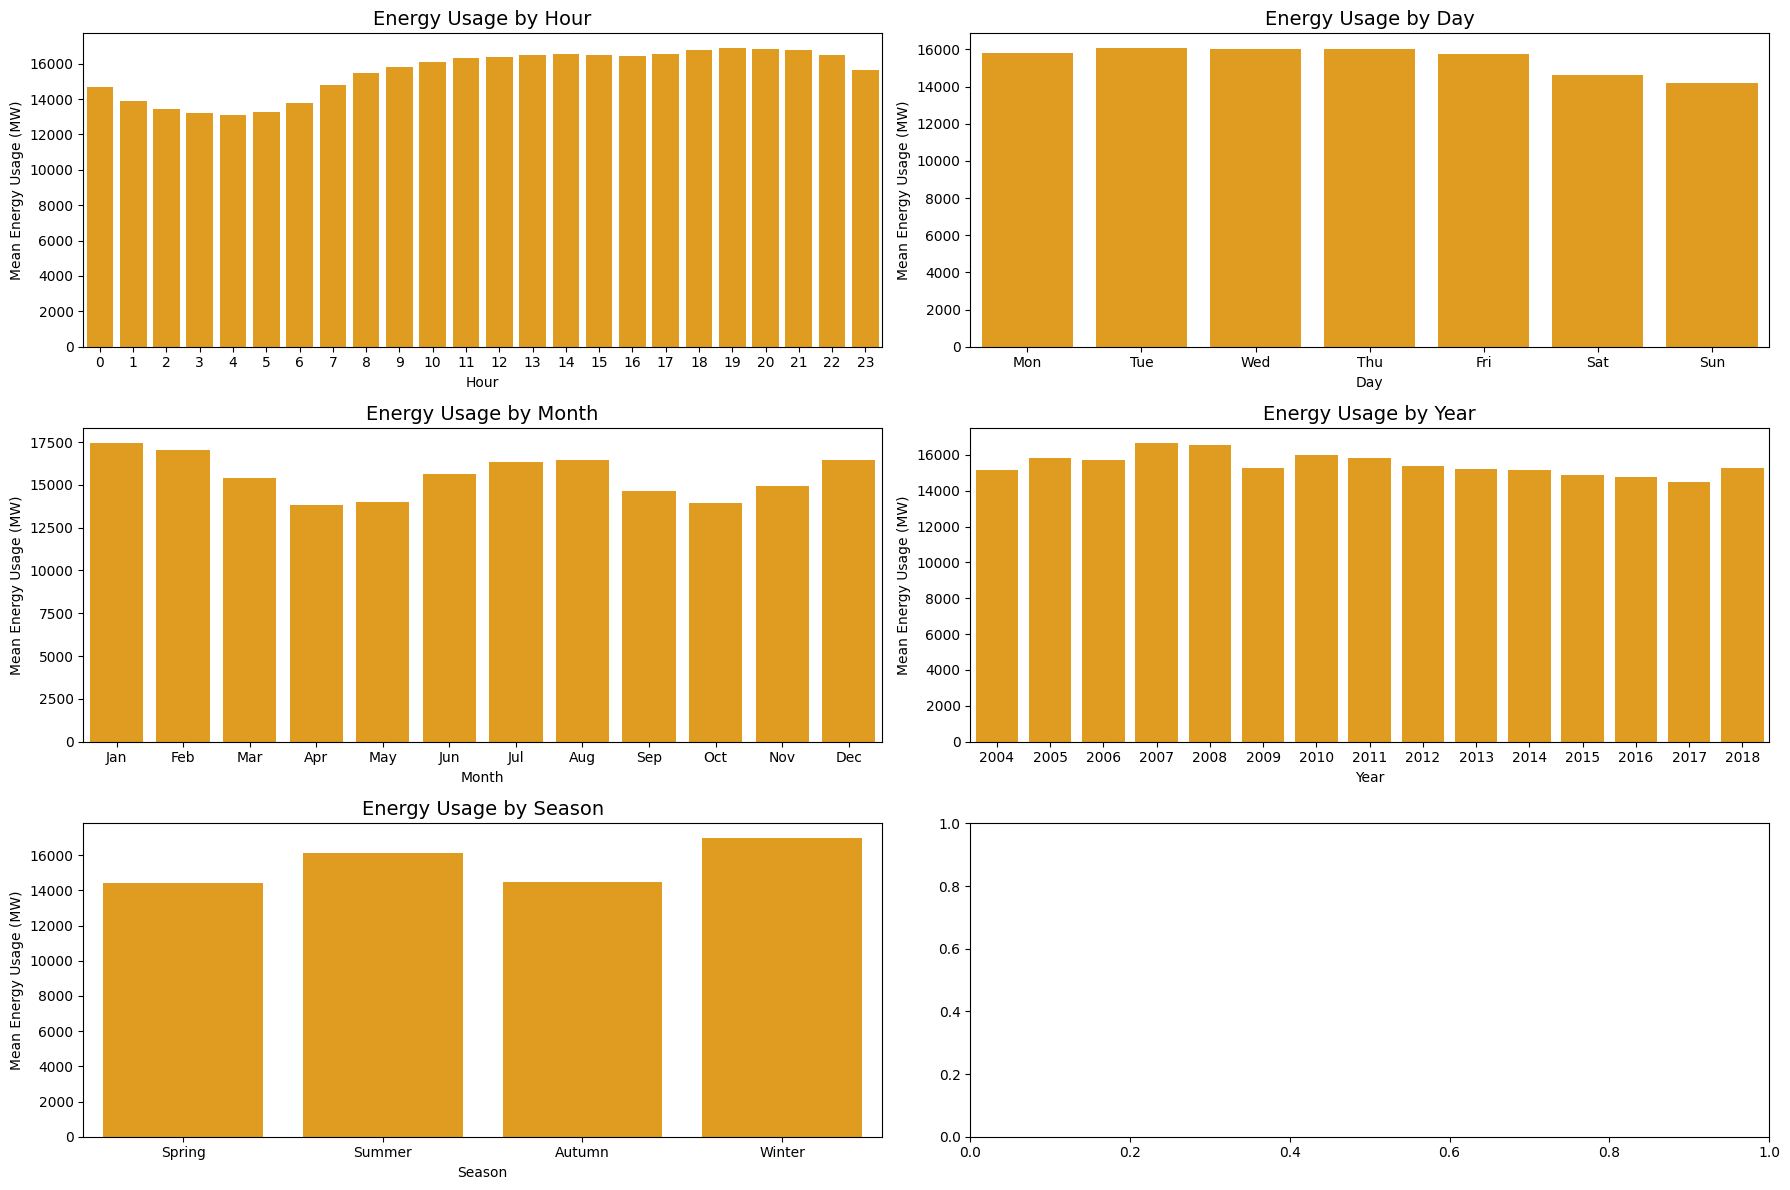

In [16]:
fig, axes = plt.subplots(3, 2, figsize=(18, 12))
axes = axes.flatten()

sns.barplot(data=df_aep, x='hour', y='AEP_MW', estimator=np.mean, errorbar=None, ax=axes[0], color='orange')
axes[0].set_title('Energy Usage by Hour', fontsize=14)
axes[0].set_xlabel('Hour')
axes[0].set_ylabel('Mean Energy Usage (MW)')

sns.barplot(data=df_aep, x='day', y='AEP_MW', estimator=np.mean, errorbar=None, ax=axes[1], color='orange')
axes[1].set_title('Energy Usage by Day', fontsize=14)
axes[1].set_xlabel('Day')
axes[1].set_ylabel('Mean Energy Usage (MW)')
axes[1].set_xticks(range(0, 7))
axes[1].set_xticklabels(['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'])


sns.barplot(data=df_aep, x='month', y='AEP_MW', estimator=np.mean, errorbar=None, ax=axes[2], color='orange')
axes[2].set_title('Energy Usage by Month', fontsize=14)
axes[2].set_xlabel('Month')
axes[2].set_ylabel('Mean Energy Usage (MW)')
axes[2].set_xticks(range(0, 12))
axes[2].set_xticklabels(['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec'])

sns.barplot(data=df_aep, x='year', y='AEP_MW', estimator=np.mean, errorbar=None, ax=axes[3], color='orange')
axes[3].set_title('Energy Usage by Year', fontsize=14)
axes[3].set_xlabel('Year')
axes[3].set_ylabel('Mean Energy Usage (MW)')

sns.barplot(data=df_aep, x='season', y='AEP_MW', estimator=np.mean, errorbar=None, ax=axes[4], color='orange')
axes[4].set_title('Energy Usage by Season', fontsize=14)
axes[4].set_xlabel('Season')
axes[4].set_ylabel('Mean Energy Usage (MW)')
axes[4].set_xticks([0, 1, 2, 3])
axes[4].set_xticklabels(['Spring', 'Summer', 'Autumn', 'Winter'])

plt.tight_layout()
plt.show()

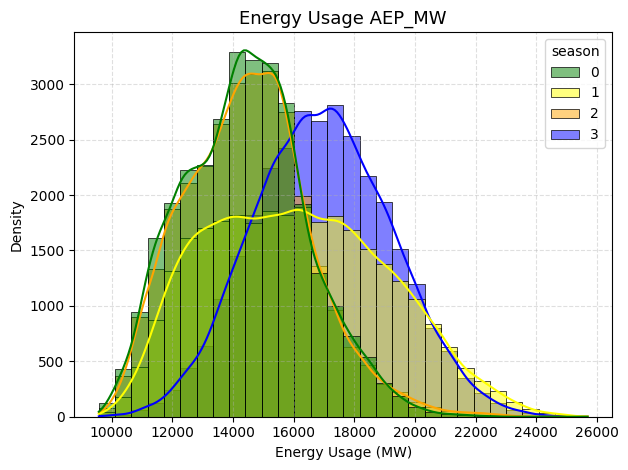

In [17]:
sns.histplot(df_aep[['AEP_MW', 'year', 'season']], 
             x='AEP_MW',
             kde=True,
             bins=30,
             hue='season',
             palette=['green', 'yellow', 'orange', 'blue'],
             alpha=0.5,
             linewidth=0.5)

plt.title('Energy Usage AEP_MW', fontsize=13)
plt.xlabel('Energy Usage (MW)')
plt.ylabel('Density')
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

- **ACF** and **PACF**

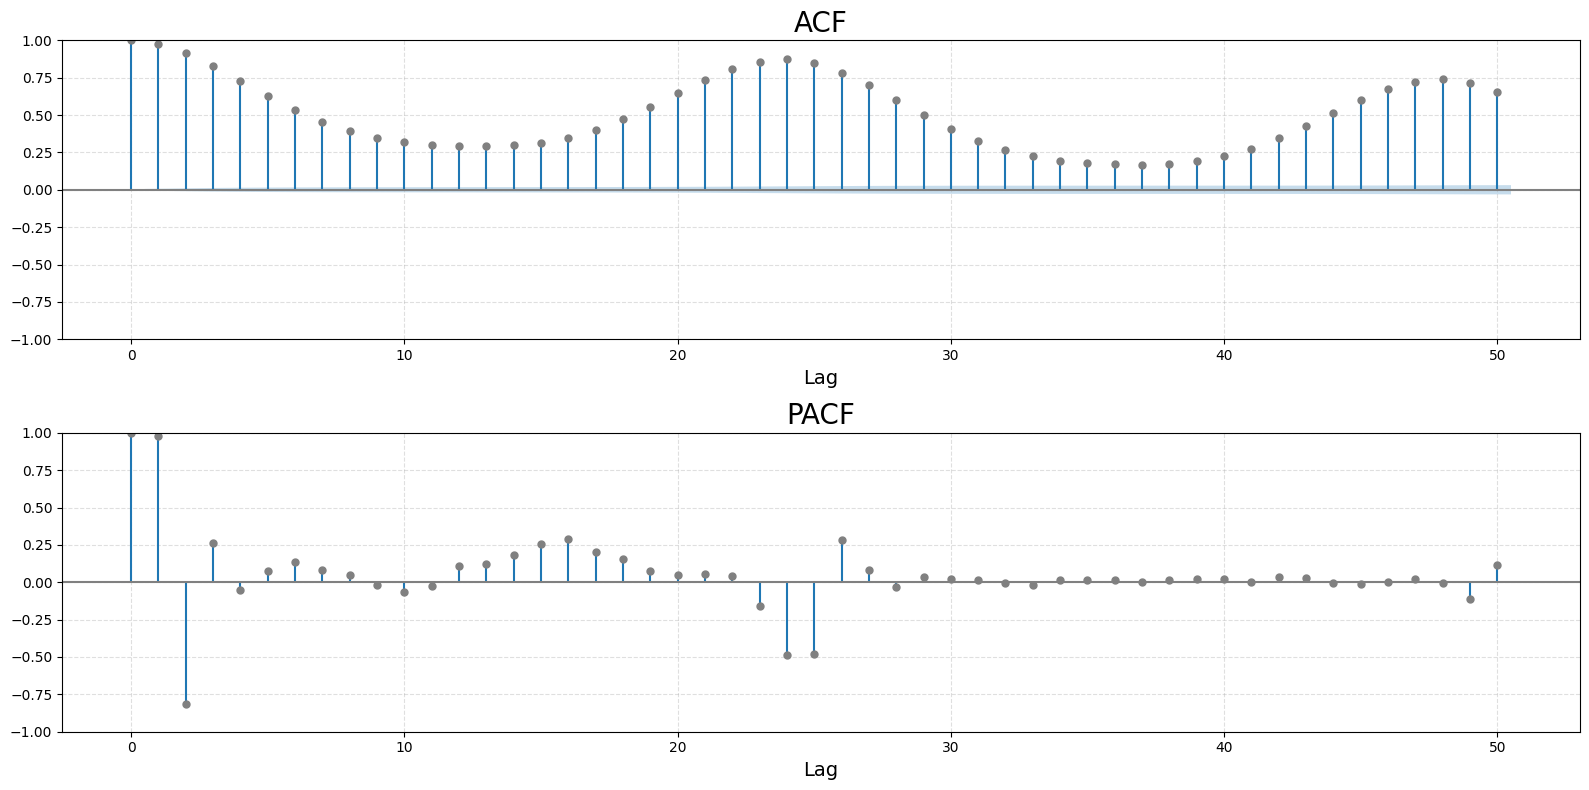

In [18]:
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(16, 8))
# ACF
plot_acf(df_aep['AEP_MW'], lags=50, ax=axes[0], color='grey', alpha=0.05)
axes[0].grid(True, linestyle='--', alpha=0.4)
axes[0].set_title('ACF', fontsize=20)
axes[0].set_xlabel('Lag',  fontsize=14)
# PACF
plot_pacf(df_aep['AEP_MW'], lags=50, ax=axes[1], color='grey', alpha=0.05)
axes[1].grid(True, linestyle='--', alpha=0.4)
axes[1].set_title('PACF', fontsize=20)
axes[1].set_xlabel('Lag', fontsize=14)

plt.tight_layout()
plt.show()

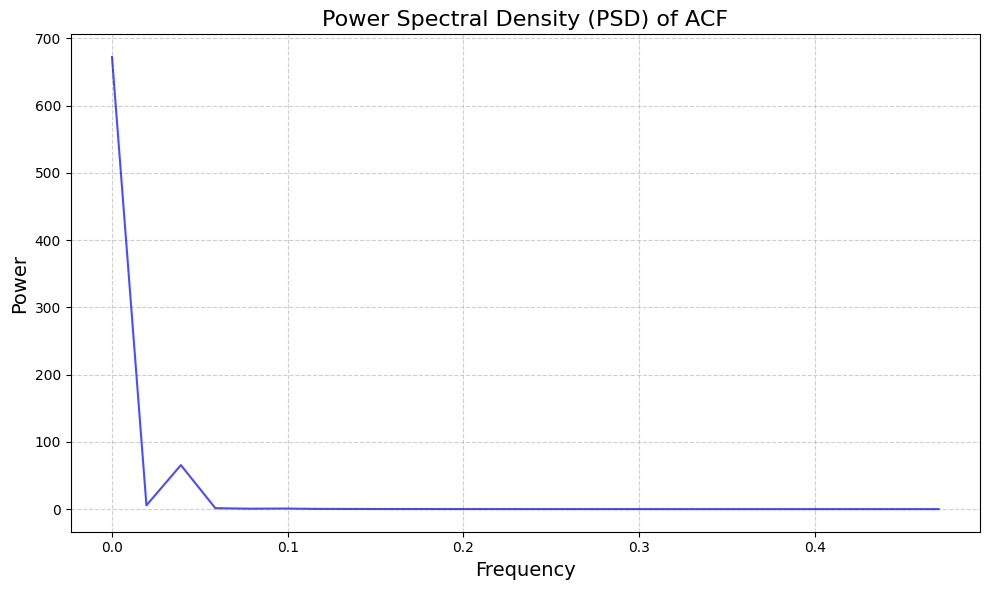

In [19]:
acf_values = acf(df_aep['AEP_MW'], nlags=50)

# Apply Fourier Transform to the ACF values
n = len(acf_values)
acf_fft = fft(acf_values)  # Compute FFT of ACF
frequencies = fftfreq(n)  # Get frequency bins

# Compute Power Spectral Density (PSD)
psd = np.abs(acf_fft)**2

# Plot the PSD
plt.figure(figsize=(10, 6))
plt.plot(frequencies[:n//2], psd[:n//2], color='blue', alpha=0.7)
plt.title('Power Spectral Density (PSD) of ACF', fontsize=16)
plt.xlabel('Frequency', fontsize=14)
plt.ylabel('Power', fontsize=14)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()


## 3. Training & Test Dataset
We split the data into training and test datasets for ARIMA modeling to evaluate the model's ability to generalize and make accurate predictions on unseen data. The training set is used to fit the ARIMA model, while the test set helps assess its forecasting performance and ensure it doesn't overfit.

- **Training dataset**: values before 2016
- **Test dataset**: values after 2016

In [20]:
# Train Test Split
df_train, df_test = df_aep[df_aep.index < '2016-01-01'], df_aep[df_aep.index >= '2016-01-01']

# Calculate percentages
train_size = len(df_train)
test_size = len(df_test)
total_size = train_size + test_size
train_per = (train_size / total_size) * 100
test_per = (test_size / total_size) * 100

print('TRAINING & TEST DATASET\n')
print('Train dataset:', len(df_train), f'({train_per:.2f}%)')
print('Testn dataset:', len(df_test), f'({test_per:.2f}%)')

TRAINING & TEST DATASET

Train dataset: 98593 (81.30%)
Testn dataset: 22680 (18.70%)


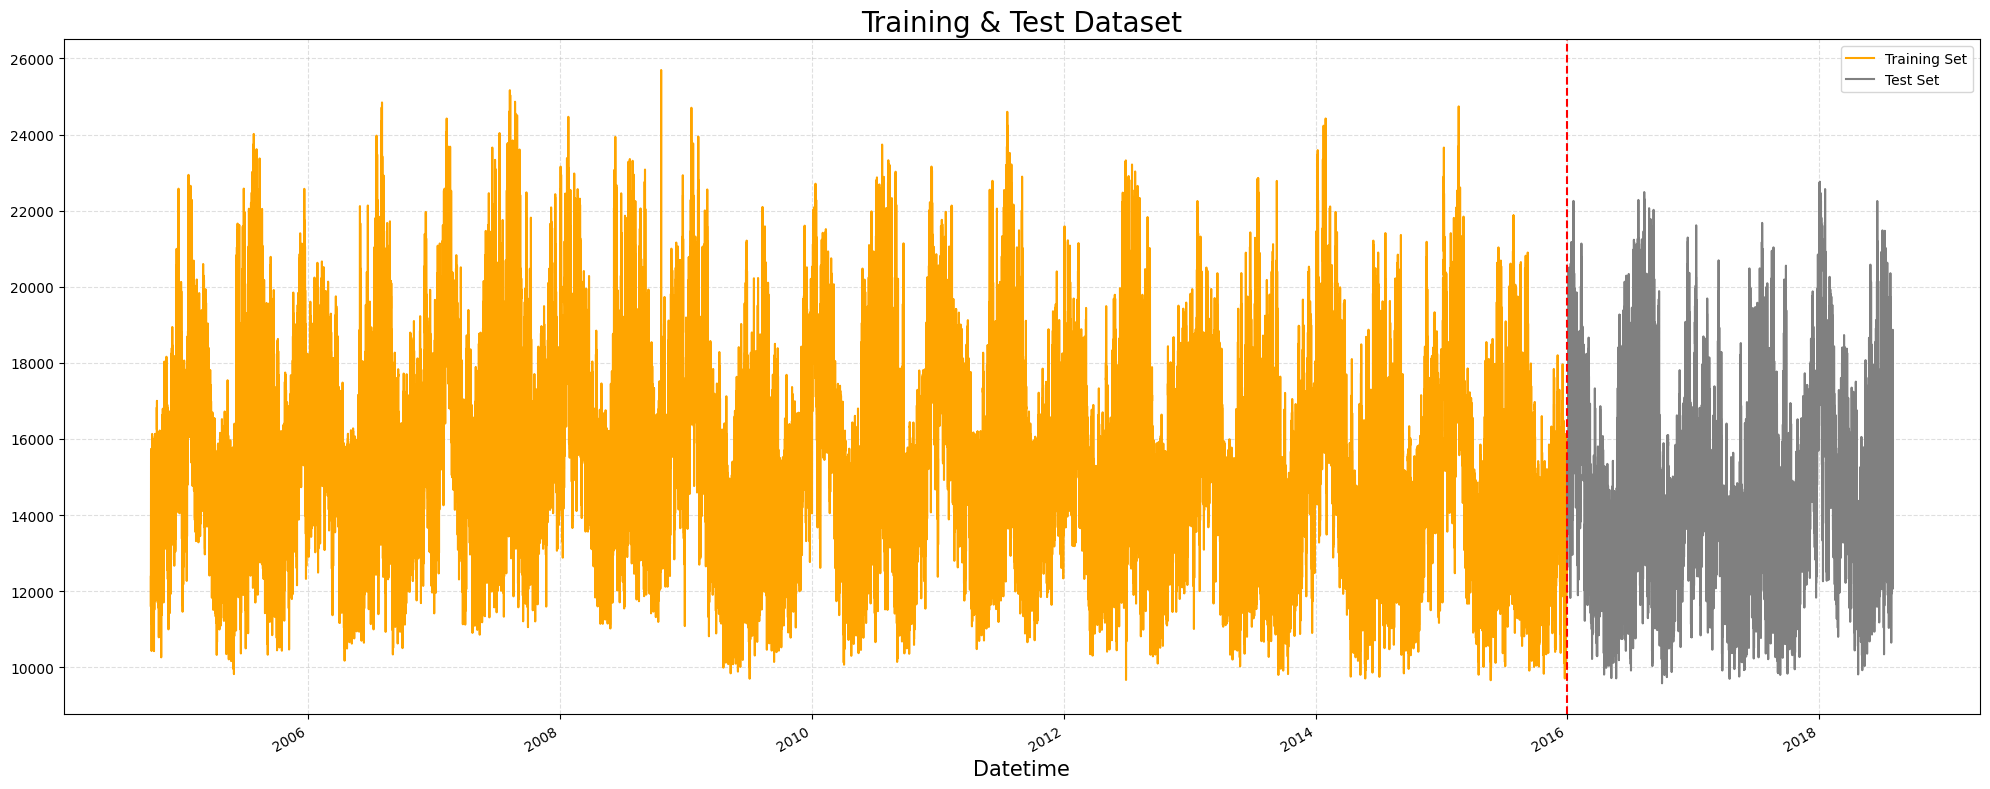

In [21]:
# Display diagram with train/test data
plt.figure(figsize=(20,8))

df_train['AEP_MW'].plot(label='Training Set', color = 'orange')
df_test['AEP_MW'].plot(label='Test Set', color = 'grey')
plt.axvline('2016-01-01', color='red', ls='--', lw=1.5)
plt.title('Training & Test Dataset', fontsize=20)
plt.xlabel('Datetime', fontsize = 15)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

# ARIMA Implementation

TRAINING & TEST DATASET

Train dataset: 4109 (81.30%)
Test dataset: 945 (18.70%)


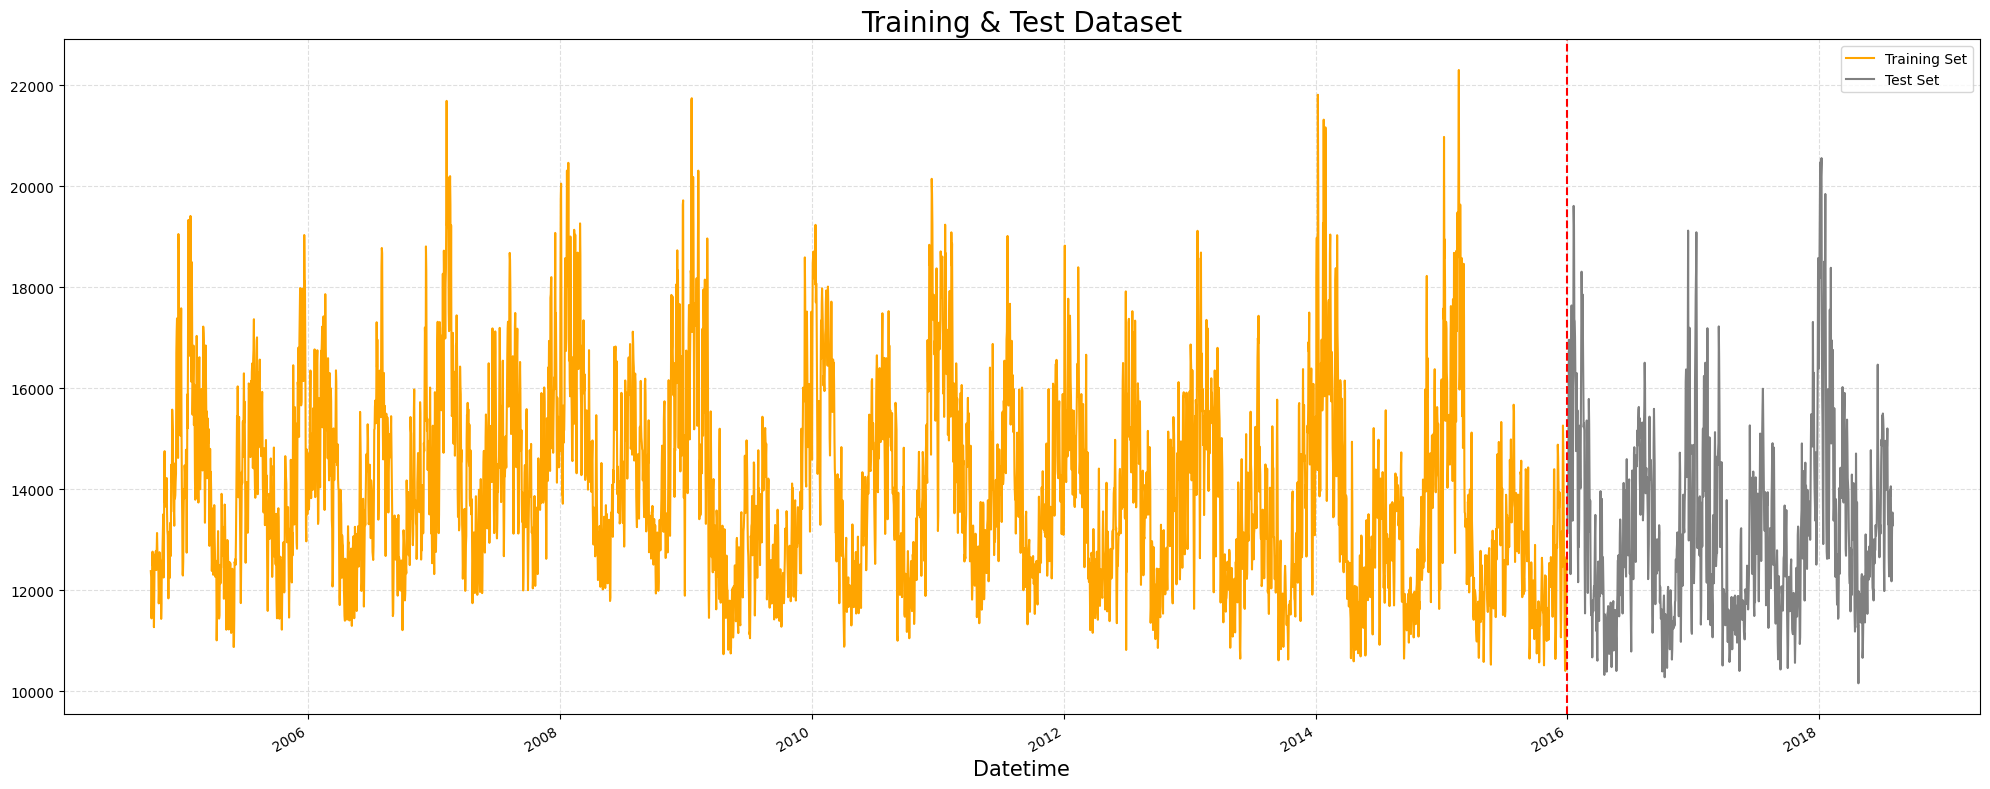

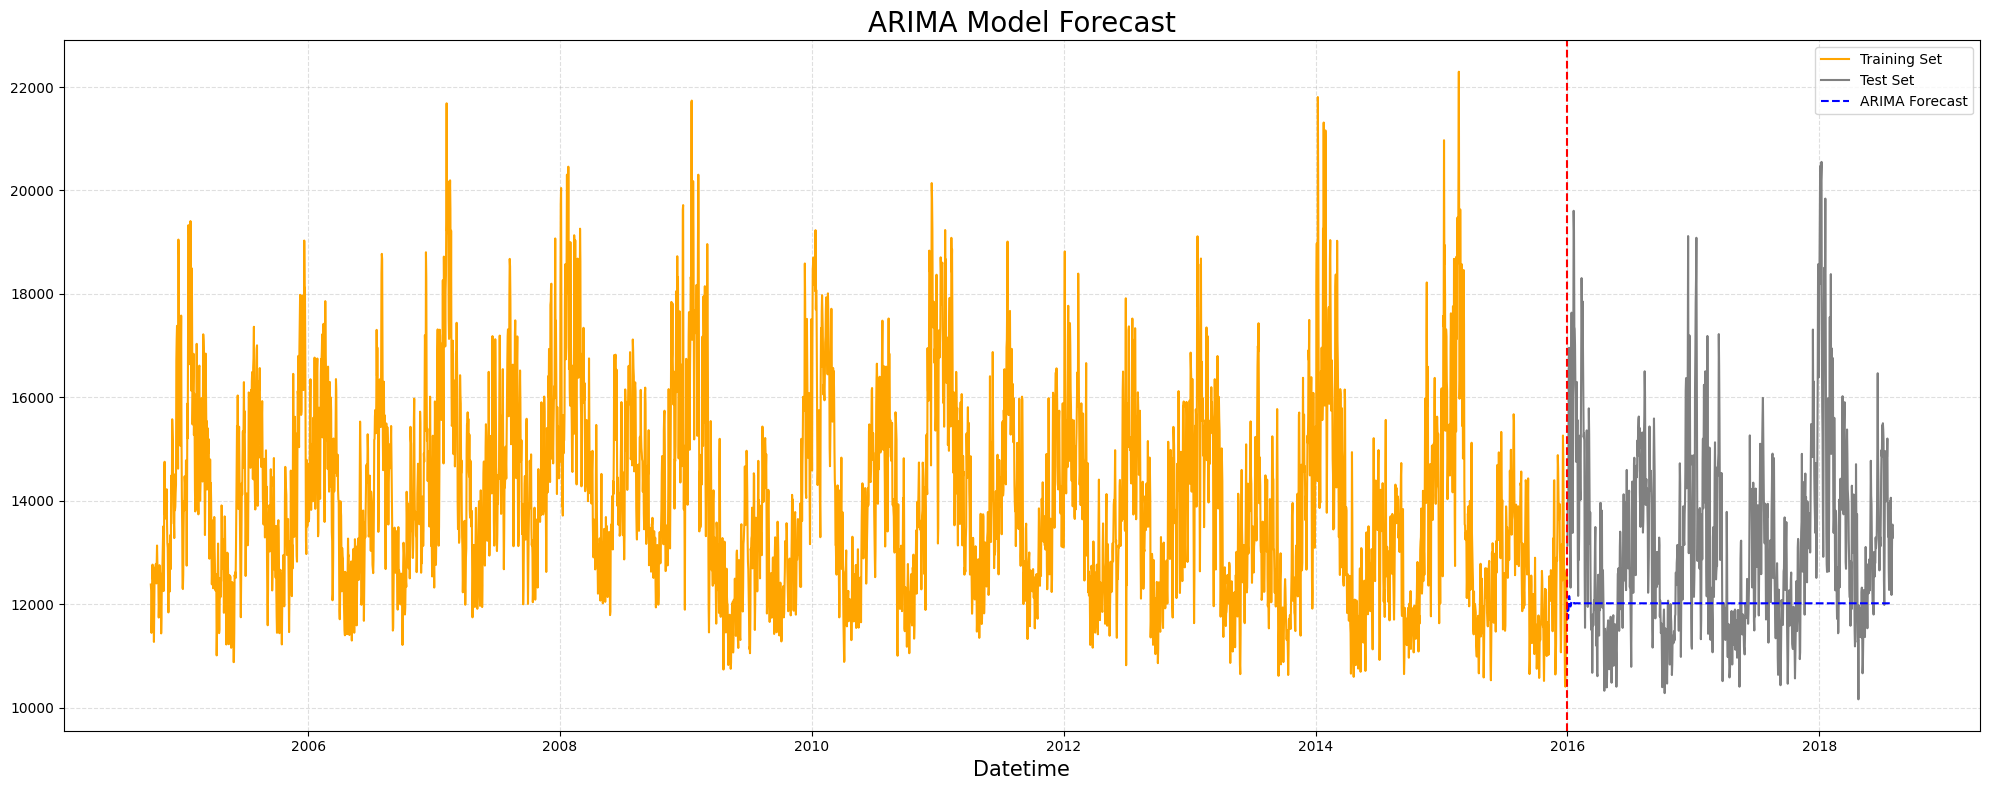

In [22]:
# Assuming you already have your 'df_aep' dataframe and datetime index

# Remove duplicates by keeping the first occurrence or aggregate (choose one of the following)
df_aep = df_aep.loc[~df_aep.index.duplicated(keep='first')]  # Option 1: Remove duplicates
# df_aep = df_aep.groupby(df_aep.index).mean()  # Option 2: Aggregate duplicates

# Set frequency of the datetime index (assuming daily frequency)
df_aep = df_aep.asfreq('D')

# Train Test Split
df_train, df_test = df_aep[df_aep.index < '2016-01-01'], df_aep[df_aep.index >= '2016-01-01']

# Calculate percentages
train_size = len(df_train)
test_size = len(df_test)
total_size = train_size + test_size
train_per = (train_size / total_size) * 100
test_per = (test_size / total_size) * 100

print('TRAINING & TEST DATASET\n')
print('Train dataset:', len(df_train), f'({train_per:.2f}%)')
print('Test dataset:', len(df_test), f'({test_per:.2f}%)')

# Display diagram with train/test data
plt.figure(figsize=(20, 8))

df_train['AEP_MW'].plot(label='Training Set', color='orange')
df_test['AEP_MW'].plot(label='Test Set', color='grey')
plt.axvline(pd.to_datetime('2016-01-01'), color='red', ls='--', lw=1.5)  # Convert to datetime
plt.title('Training & Test Dataset', fontsize=20)
plt.xlabel('Datetime', fontsize=15)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

# Fit ARIMA model on the training set
model = ARIMA(df_train['AEP_MW'], order=(5, 1, 0))
model_fit = model.fit()

# Forecast the future values
forecast = model_fit.forecast(steps=len(df_test))

# Plot the predictions along with the actual values
plt.figure(figsize=(20, 8))
plt.plot(df_train['AEP_MW'], label='Training Set', color='orange')
plt.plot(df_test['AEP_MW'], label='Test Set', color='grey')
plt.plot(df_test.index, forecast, label='ARIMA Forecast', color='blue', linestyle='--')
plt.axvline(pd.to_datetime('2016-01-01'), color='red', ls='--', lw=1.5)  # Convert to datetime
plt.title('ARIMA Model Forecast', fontsize=20)
plt.xlabel('Datetime', fontsize=15)
plt.legend()
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()
